# Democracy, Income and Digital Transparency (2025)

**Team Yellow** · end-to-end analysis

**Question:** Do more democratic countries have more digital transparency, holding income constant?

This notebook goes from the raw downloads to the final regressions, in order:

1. Settings
2. Transparency index (World Bank GovTech data)
3. Democracy (V-Dem)
4. Income (World Bank WDI)
5. Harmonise and merge
6. Describe the data
7. Main regressions (tests H1)
8. Robustness checks
9. Countries that break the pattern
10. Save results

**How to run:** open this notebook from the repository root, so the paths `data/raw/...` work, then choose *Run All*. The raw files are never changed; everything new is saved to `data/processed/` and `outputs/`.

## 1. Settings

In [1]:
import os
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# Raw files (original downloads, never edited)
GOVTECH_FILE = "data/raw/WBG_GovTech_Dataset_Dec2025_03102026.xlsx"
VDEM_ZIP     = "data/raw/V-Dem-CY-Core-v16_csv_03102026.zip"
GDP_PPP_ZIP  = "data/raw/GDP_PPP_03102026.zip"
GDP_USD_ZIP  = "data/raw/GDP_USD_03102026.zip"

YEAR = 2025

# Where to save new files
os.makedirs("data/processed", exist_ok=True)
os.makedirs("outputs/figures", exist_ok=True)

## 2. Transparency index (World Bank GovTech)

The index combines 28 GovTech sub-indicators in 8 themes. Each indicator is rescaled to 0–1 by dividing by its highest possible value, then multiplied by its weight. The weights add up to 100, so the index runs from **0 (no digital transparency) to 100 (full)**.

| Theme | Weight |
|---|---|
| Open Data | 20 |
| Right to Information (RTI) law | 20 |
| E-Procurement | 15 |
| Open Government | 15 |
| Citizen Participation | 10 |
| Citizen Feedback | 10 |
| Engagement Statistics | 5 |
| Job Portal | 5 |

### 2a. Load the 2025 GovTech data

In [2]:
govtech = pd.read_excel(GOVTECH_FILE, sheet_name="GTMI_Data", na_values=["-"])  # "-" means no answer

govtech["Code"] = govtech["Code"].astype(str).str.strip()   # remove hidden spaces
govtech = govtech[govtech["Year"] == YEAR]                  # keep 2025 only
govtech = govtech[govtech["Code"].str.len() == 3]           # drop summary rows (real codes have 3 letters)

print(len(govtech), "economies in GovTech", YEAR)

198 economies in GovTech 2025


### 2b. The index design

One row per indicator: its theme, its weight (% of the index) and its highest possible value in the raw data. Dividing by the highest value rescales each indicator to 0–1.

Two indicators (I-25.3 and I-30.2) have answers 1 and 2 that are both "yes", just in different forms (e.g. petitions on the same or a separate portal). They are recoded so any "yes" = 1.

In [3]:
index_design = pd.DataFrame([
    # indicator, theme,                   weight,         max value, what it asks
    ("I-29.2", "Open Data",               3.75,           3),  # how often the open data portal is updated
    ("I-29.3", "Open Data",               5.00,           2),  # contents / maturity of the portal
    ("I-29.4", "Open Data",               3.75,           2),  # updated automatically via APIs?
    ("I-29.5", "Open Data",               7.50,           1),  # portal widely used?

    ("I-37.3", "RTI Law",                 20 * 20 / 65,   1),  # entity monitoring RTI compliance?
    ("I-37.4", "RTI Law",                 20 * 45 / 65,   1),  # RTI laws actively enforced?

    ("I-12.4", "E-Procurement",           4.00,           3),  # e-procurement portal capabilities
    ("I-12.5", "E-Procurement",           5.00,           1),  # data published in the open standard (OCDS)?
    ("I-12.6", "E-Procurement",           2.00,           2),  # portal exchanges data with other systems?
    ("I-12.8", "E-Procurement",           4.00,           1),  # procurement actually done through the portal?

    ("I-28.2", "Open Government",         15 * 20 / 70,   3),  # how often the open government portal is updated
    ("I-28.3", "Open Government",         15 * 25 / 70,   2),  # contents / maturity of the portal
    ("I-28.4", "Open Government",         15 * 25 / 70,   1),  # regularly updated and actively used?

    ("I-30.2", "Citizen Participation",   10 * 15 / 80,   1),  # can citizens submit petitions? (recoded)
    ("I-30.3", "Citizen Participation",   10 * 20 / 80,   1),  # can citizens take part in policy decisions?
    ("I-30.4", "Citizen Participation",   10 * 10 / 80,   1),  # anonymous feedback possible?
    ("I-30.5", "Citizen Participation",   10 * 10 / 80,   1),  # accessible through all channels?
    ("I-30.6", "Citizen Participation",   10 * 25 / 80,   1),  # platforms actively used for decisions?

    ("I-31.2", "Citizen Feedback",        2.50,           1),  # service standards made public?
    ("I-31.3", "Citizen Feedback",        1.25,           1),  # accessible for users with disabilities?
    ("I-31.4", "Citizen Feedback",        1.25,           1),  # advanced tech (e.g. chatbots) used?
    ("I-31.5", "Citizen Feedback",        1.25,           1),  # accessible through all channels?
    ("I-31.6", "Citizen Feedback",        3.75,           1),  # feedback platforms used effectively?

    ("I-32.2", "Engagement Statistics",   5 * 15 / 85,    1),  # service delivery performance measured?
    ("I-32.3", "Engagement Statistics",   5 * 25 / 85,    1),  # engagement results published?
    ("I-32.4", "Engagement Statistics",   5 * 10 / 85,    1),  # initiative for vulnerable groups?
    ("I-32.5", "Engagement Statistics",   5 * 35 / 85,    1),  # engagement statistics published online?

    ("I-25.3", "Job Portal",              5.00,           1),  # public sector jobs on a job portal? (recoded)
], columns=["indicator", "theme", "weight", "max_value"])

print("Number of indicators:", len(index_design))
print("Weights add up to:", round(index_design["weight"].sum(), 2))   # must be 100
index_design.groupby("theme")["weight"].sum().round(2)

Number of indicators: 28
Weights add up to: 100.0


theme
Citizen Feedback         10.0
Citizen Participation    10.0
E-Procurement            15.0
Engagement Statistics     5.0
Job Portal                5.0
Open Data                20.0
Open Government          15.0
RTI Law                  20.0
Name: weight, dtype: float64

### 2c. Rescale the indicators and build the index

In [4]:
indicators = list(index_design["indicator"])

transparency = govtech[["Code", "Economy"] + indicators].copy()
transparency = transparency.rename(columns={"Code": "iso3", "Economy": "country"})

# Make sure every indicator is a number
for ind in indicators:
    transparency[ind] = pd.to_numeric(transparency[ind], errors="coerce")

# Any kind of "yes" counts as 1 for these two indicators
transparency["I-25.3"] = transparency["I-25.3"].replace({2: 1})
transparency["I-30.2"] = transparency["I-30.2"].replace({2: 1})

# Rescale every indicator to 0-1
for _, row in index_design.iterrows():
    transparency[row["indicator"]] = transparency[row["indicator"]] / row["max_value"]


def build_index(table, design):
    """Weighted sum of the rescaled indicators, scaled to 0-100."""
    total = 0
    for _, row in design.iterrows():
        total = total + table[row["indicator"]] * row["weight"]
    return total / design["weight"].sum() * 100


transparency["transparency_index"] = build_index(transparency, index_design)

# Checks
print("Rescaled values between", transparency[indicators].min().min(), "and", transparency[indicators].max().max())
print("Index between", round(transparency["transparency_index"].min(), 1), "and", round(transparency["transparency_index"].max(), 1))
print("No index (no data):", transparency.loc[transparency["transparency_index"].isna(), "country"].tolist())
transparency[["country", "transparency_index"]].head()

Rescaled values between 0.0 and 1.0
Index between 0.0 and 100.0
No index (no data): ['Nicaragua']


,country,transparency_index
2,Afghanistan,1.333333
5,Albania,98.666667
8,Algeria,28.666667
11,Andorra,9.541667
14,Angola,32.147894


## 3. Democracy (V-Dem v16)

We only need four columns from the 1,900+ in the file, so we read just those. Main predictor: **Electoral Democracy Index** (`v2x_polyarchy`, 0–1). The Liberal Democracy Index is used in one robustness check, and the regime type for describing the data.

In [5]:
vdem_columns = ["country_name", "country_text_id", "year",
                "v2x_polyarchy", "v2x_libdem", "v2x_regime"]

with zipfile.ZipFile(VDEM_ZIP) as z:
    vdem = pd.read_csv(z.open("V-Dem-CY-Core-v16.csv"), usecols=vdem_columns)

vdem = vdem[vdem["year"] == YEAR]
vdem = vdem.rename(columns={"country_text_id": "iso3",
                            "v2x_polyarchy": "polyarchy",
                            "v2x_libdem": "libdem",
                            "v2x_regime": "regime"})

regime_names = {0: "Closed autocracy", 1: "Electoral autocracy",
                2: "Electoral democracy", 3: "Liberal democracy"}
vdem["regime_label"] = vdem["regime"].map(regime_names)

print(len(vdem), "countries in V-Dem", YEAR)
print(vdem["regime_label"].value_counts())

179 countries in V-Dem 2025
regime_label
Electoral autocracy    57
Electoral democracy    56
Closed autocracy       35
Liberal democracy      31
Name: count, dtype: int64


**Palestine.** V-Dem scores the West Bank (`PSE`) and Gaza (`PSG`) separately, while GovTech and WDI treat Palestine as one economy. We use the average of the two scores under `PSE`, keep the West Bank's regime type, and drop the Gaza row.

In [6]:
palestine = vdem[vdem["iso3"].isin(["PSE", "PSG"])]
print(palestine[["country_name", "polyarchy", "libdem", "regime_label"]])

vdem.loc[vdem["iso3"] == "PSE", "polyarchy"] = palestine["polyarchy"].mean()
vdem.loc[vdem["iso3"] == "PSE", "libdem"] = palestine["libdem"].mean()
vdem = vdem[vdem["iso3"] != "PSG"]

vdem = vdem[["iso3", "polyarchy", "libdem", "regime_label"]]

              country_name  polyarchy  libdem         regime_label
18785  Palestine/West Bank      0.214   0.114  Electoral autocracy
19661       Palestine/Gaza      0.128   0.058     Closed autocracy


## 4. Income (World Bank WDI)

Two GDP per capita measures for 2025: **PPP, constant 2021 international $** (main control) and **current US$** (robustness check). We use the natural log of GDP, because extra income matters more for poor countries than for rich ones.

The country metadata file in each zip gives region and income group. Rows without a region are group totals (e.g. "World"), so we drop them.

In [7]:
def read_wdi(zip_path, new_name):
    """Read one WDI zip and return the 2025 values as two columns: iso3, new_name."""
    with zipfile.ZipFile(zip_path) as z:
        data_file = [name for name in z.namelist() if name.startswith("API_")][0]
        data = pd.read_csv(z.open(data_file), skiprows=4)     # 4 note lines above the header
    data = data[["Country Code", str(YEAR)]]
    return data.rename(columns={"Country Code": "iso3", str(YEAR): new_name})


# Country list with region and income group (drops group totals like "World")
with zipfile.ZipFile(GDP_PPP_ZIP) as z:
    meta_file = [name for name in z.namelist() if name.startswith("Metadata_Country")][0]
    countries = pd.read_csv(z.open(meta_file))

countries = countries[countries["Region"].notna()]
countries = countries[["Country Code", "Region", "IncomeGroup"]]
countries = countries.rename(columns={"Country Code": "iso3", "Region": "region",
                                      "IncomeGroup": "income_group"})

gdp = countries.merge(read_wdi(GDP_PPP_ZIP, "gdp_pc_ppp"), on="iso3", how="left")
gdp = gdp.merge(read_wdi(GDP_USD_ZIP, "gdp_pc_usd"), on="iso3", how="left")

gdp["ln_gdp_pc_ppp"] = np.log(gdp["gdp_pc_ppp"])
gdp["ln_gdp_pc_usd"] = np.log(gdp["gdp_pc_usd"])

print(len(gdp), "economies in WDI")
print("Missing PPP GDP:", gdp["gdp_pc_ppp"].isna().sum(), "| Missing US$ GDP:", gdp["gdp_pc_usd"].isna().sum())

217 economies in WDI
Missing PPP GDP: 32 | Missing US$ GDP: 31


## 5. Harmonise and merge

GovTech uses two old World Bank codes. We change them to the codes V-Dem and WDI use:

- Kosovo: `KSV` → `XKX`
- West Bank and Gaza: `WBG` → `PSE`

Then we merge, printing who drops out at each step.

In [8]:
transparency["iso3"] = transparency["iso3"].replace({"KSV": "XKX", "WBG": "PSE"})

# Step 1: who is in GovTech but not in V-Dem?
no_vdem = transparency[~transparency["iso3"].isin(vdem["iso3"])]
print("In GovTech but not V-Dem (dropped):", len(no_vdem))
print(sorted(no_vdem["country"]), "\n")

# Step 2: keep countries that are in both (inner merge)
df = transparency[["iso3", "country", "transparency_index"]].merge(vdem, on="iso3", how="inner")

# Step 3: drop countries with no transparency data (Nicaragua)
print("No transparency data (dropped):", df.loc[df["transparency_index"].isna(), "country"].tolist(), "\n")
df = df.dropna(subset=["transparency_index"])

# Step 4: add GDP, keeping every country even if GDP is missing (left merge)
df = df.merge(gdp, on="iso3", how="left")
print("No 2025 PPP GDP (kept, but left out of GDP models):")
print(sorted(df.loc[df["gdp_pc_ppp"].isna(), "country"]))

In GovTech but not V-Dem (dropped): 22
['Andorra', 'Antigua and Barbuda', 'Bahamas', 'Belize', 'Brunei Darussalam', 'Dominica', 'Grenada', 'Kiribati', 'Liechtenstein', 'Macao SAR, China', 'Marshall Islands', 'Micronesia, Fed. Sts.', 'Monaco', 'Nauru', 'Palau', 'Samoa', 'San Marino', 'St. Kitts and Nevis', 'St. Lucia', 'St. Vincent and the Grenadines', 'Tonga', 'Tuvalu'] 

No transparency data (dropped): ['Nicaragua'] 

No 2025 PPP GDP (kept, but left out of GDP models):
['Afghanistan', 'Cuba', 'Eritrea', 'Korea, DPR', 'Lebanon', 'South Sudan', 'Syrian Arab Republic', 'Taiwan, China', 'United Arab Emirates', 'Venezuela, RB', 'Yemen']


We use two samples:

- **`sample`**: countries with transparency, democracy *and* PPP GDP. Used for all main models, so Models 1 and 2 compare the same countries.
- **`full`**: every country with transparency and democracy, even without GDP. Used in one robustness check, because the countries missing GDP are mostly autocracies.

In [9]:
full = df.copy()
sample = df.dropna(subset=["ln_gdp_pc_ppp"]).copy()

print("Full sample:", len(full), "countries")
print("Main sample (with GDP):", len(sample), "countries")

full.to_csv("data/processed/analysis_dataset_2025.csv", index=False)
print("Saved data/processed/analysis_dataset_2025.csv")

Full sample: 175 countries
Main sample (with GDP): 164 countries
Saved data/processed/analysis_dataset_2025.csv


## 6. Describe the data

In [10]:
sample[["transparency_index", "polyarchy", "libdem", "gdp_pc_ppp"]].describe().round(2)

,transparency_index,polyarchy,libdem,gdp_pc_ppp
count,164.00,164.00,164.00,164.00
mean,49.51,0.51,0.39,26838.30
std,30.79,0.26,0.26,26932.48
min,0.00,0.02,0.02,1066.51
25%,22.04,0.26,0.13,6144.42
50%,50.96,0.51,0.38,17166.52
75%,77.24,0.74,0.62,40924.65
max,100.00,0.91,0.88,139592.61


**Sub-question 1:** how does transparency differ across regime types?

In [11]:
regime_order = ["Closed autocracy", "Electoral autocracy", "Electoral democracy", "Liberal democracy"]

by_regime = sample.groupby("regime_label")["transparency_index"].agg(["count", "mean", "median"])
by_regime = by_regime.reindex(regime_order).round(1)
by_regime

,count,mean,median
regime_label,,,
Closed autocracy,26,37.5,23.5
Electoral autocracy,52,44.0,38.5
Electoral democracy,56,48.8,51.8
Liberal democracy,30,70.7,77.1


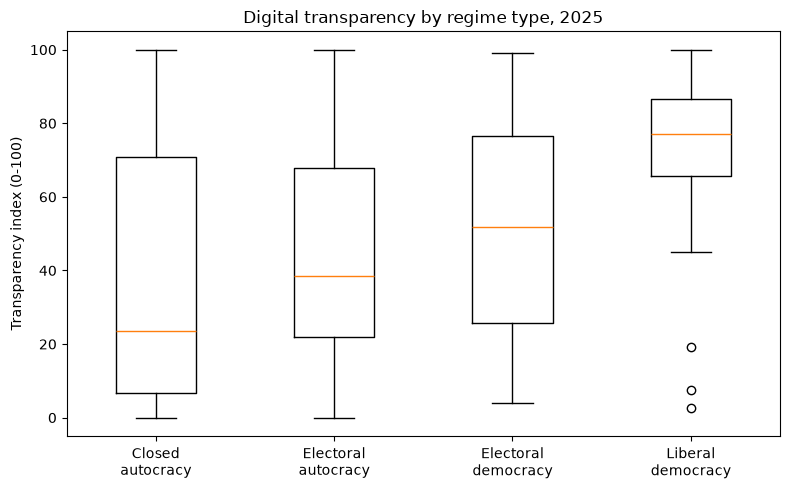

In [12]:
groups = [sample.loc[sample["regime_label"] == r, "transparency_index"] for r in regime_order]

plt.figure(figsize=(8, 5))
plt.boxplot(groups)
plt.xticks([1, 2, 3, 4], ["Closed\nautocracy", "Electoral\nautocracy", "Electoral\ndemocracy", "Liberal\ndemocracy"])
plt.ylabel("Transparency index (0-100)")
plt.title("Digital transparency by regime type, 2025")
plt.tight_layout()
plt.savefig("outputs/figures/boxplot_regime.png", dpi=150)
plt.show()

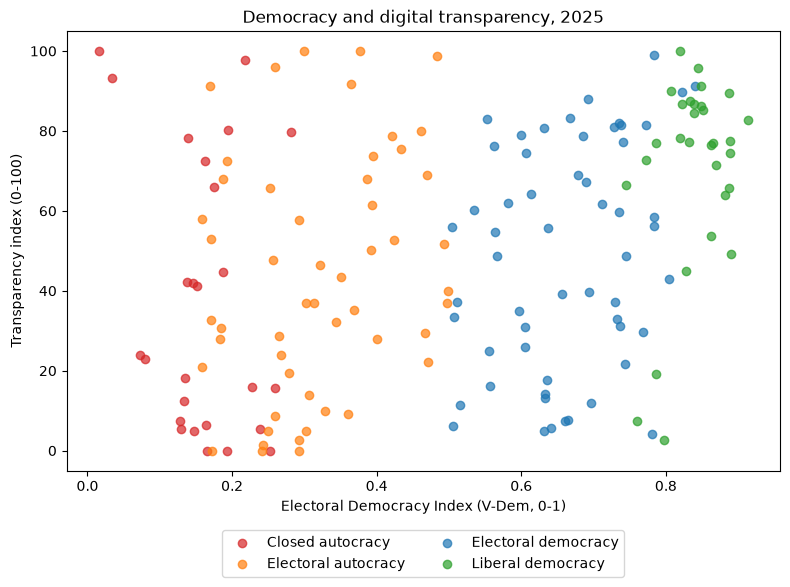

In [13]:
colours = {"Closed autocracy": "tab:red", "Electoral autocracy": "tab:orange",
           "Electoral democracy": "tab:blue", "Liberal democracy": "tab:green"}

plt.figure(figsize=(8, 6))
for regime in regime_order:
    part = sample[sample["regime_label"] == regime]
    plt.scatter(part["polyarchy"], part["transparency_index"], label=regime,
                color=colours[regime], alpha=0.7)

plt.xlabel("Electoral Democracy Index (V-Dem, 0-1)")
plt.ylabel("Transparency index (0-100)")
plt.title("Democracy and digital transparency, 2025")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)   # legend below the chart
plt.tight_layout()
plt.savefig("outputs/figures/scatter_democracy_transparency.png", dpi=150)
plt.show()

## 7. Main regressions

- **Model 1:** transparency ~ democracy
- **Model 2:** transparency ~ democracy + log GDP per capita → **tests H1**

**H1** is supported if the democracy coefficient in Model 2 is positive and significant (p < 0.05).

`cov_type="HC1"` gives *robust standard errors*, which stay reliable even if the spread of the errors differs across countries. It's standard in cross-country regressions.

In [14]:
m1 = smf.ols("transparency_index ~ polyarchy", data=sample).fit(cov_type="HC1")
m2 = smf.ols("transparency_index ~ polyarchy + ln_gdp_pc_ppp", data=sample).fit(cov_type="HC1")

print(m2.summary())

                            OLS Regression Results                            
Dep. Variable:     transparency_index   R-squared:                       0.356
Model:                            OLS   Adj. R-squared:                  0.348
Method:                 Least Squares   F-statistic:                     63.35
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           5.06e-21
Time:                        16:20:17   Log-Likelihood:                -758.20
No. Observations:                 164   AIC:                             1522.
Df Residuals:                     161   BIC:                             1532.
Df Model:                           2                                         
Covariance Type:                  HC1                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept       -96.1365     13.932     -6.901

In [15]:
def key_results(model, name, democracy_var="polyarchy"):
    """The numbers we care about from one model, as one row."""
    return {
        "model": name,
        "countries": int(model.nobs),
        "democracy_coef": round(model.params[democracy_var], 2),
        "democracy_p": round(model.pvalues[democracy_var], 4),
        "r_squared": round(model.rsquared, 3),
    }


main_results = pd.DataFrame([
    key_results(m1, "Model 1: democracy only"),
    key_results(m2, "Model 2: democracy + log GDP (PPP)"),
])
main_results

,model,countries,democracy_coef,democracy_p,r_squared
0,Model 1: democracy only,164,41.04,0.0000,0.117
1,Model 2: democracy + log GDP (PPP),164,9.54,0.2693,0.356


In [16]:
coef = m2.params["polyarchy"]
p = m2.pvalues["polyarchy"]

print(f"Model 1 democracy coefficient: {m1.params['polyarchy']:.1f}")
print(f"Model 2 democracy coefficient: {coef:.1f} (p = {p:.4f})")
print(f"Meaning: a 0.1 rise in the democracy score goes with a {coef / 10:.1f}-point higher index, at the same income level.\n")

if coef > 0 and p < 0.05:
    print("Result: reject H0. Democracy is positively and significantly linked to transparency, holding income constant (H1 supported).")
else:
    print("Result: fail to reject H0. No significant link between democracy and transparency once income is controlled for.")

Model 1 democracy coefficient: 41.0
Model 2 democracy coefficient: 9.5 (p = 0.2693)
Meaning: a 0.1 rise in the democracy score goes with a 1.0-point higher index, at the same income level.

Result: fail to reject H0. No significant link between democracy and transparency once income is controlled for.


## 8. Robustness checks

Each check changes **one thing** in Model 2. If the democracy coefficient stays positive and significant across them, the result is robust.

| Check | What changes |
|---|---|
| Model 3 | Liberal Democracy Index instead of Electoral Democracy |
| Model 4 | GDP in current US$ instead of PPP |
| Model 5 | Adds world region (compares countries within the same region) |
| Model 6 | Model 1 on the full sample, including countries without GDP |
| Leave-one-theme-out | Index rebuilt 8 times, each time without one theme |

In [17]:
usd_sample = df.dropna(subset=["ln_gdp_pc_usd"])

m3 = smf.ols("transparency_index ~ libdem + ln_gdp_pc_ppp", data=sample).fit(cov_type="HC1")
m4 = smf.ols("transparency_index ~ polyarchy + ln_gdp_pc_usd", data=usd_sample).fit(cov_type="HC1")
m5 = smf.ols("transparency_index ~ polyarchy + ln_gdp_pc_ppp + C(region)", data=sample).fit(cov_type="HC1")
m6 = smf.ols("transparency_index ~ polyarchy", data=full).fit(cov_type="HC1")

robustness = pd.DataFrame([
    key_results(m2, "Model 2 (main, for comparison)"),
    key_results(m3, "Model 3: Liberal Democracy Index", democracy_var="libdem"),
    key_results(m4, "Model 4: GDP in US$"),
    key_results(m5, "Model 5: + region"),
    key_results(m6, "Model 6: no GDP, full sample"),
])
robustness

,model,countries,democracy_coef,democracy_p,r_squared
0,"Model 2 (main, for comparison)",164,9.54,0.2693,0.356
1,Model 3: Liberal Democracy Index,164,11.82,0.1845,0.358
2,Model 4: GDP in US$,165,6.27,0.5057,0.321
3,Model 5: + region,164,9.40,0.3307,0.395
4,"Model 6: no GDP, full sample",175,46.76,0.0000,0.152


**Leave-one-theme-out.** The theme weights are our own choice. To check that no single theme drives the result, we rebuild the index without each theme in turn (re-scaled to 0–100) and re-run Model 2.

In [18]:
leave_one_out = []

for theme in index_design["theme"].unique():
    smaller_design = index_design[index_design["theme"] != theme]

    # Rebuild the index without this theme
    temp = transparency[["iso3"]].copy()
    temp["index_without_theme"] = build_index(transparency, smaller_design)

    # Run Model 2 with the new index
    data = sample.merge(temp, on="iso3", how="left")
    model = smf.ols("index_without_theme ~ polyarchy + ln_gdp_pc_ppp", data=data).fit(cov_type="HC1")
    leave_one_out.append(key_results(model, "Without " + theme))

leave_one_out = pd.DataFrame(leave_one_out)
leave_one_out

,model,countries,democracy_coef,democracy_p,r_squared
0,Without Open Data,164,10.12,0.2650,0.292
1,Without RTI Law,164,1.91,0.8260,0.365
2,Without E-Procurement,164,10.15,0.2458,0.375
3,Without Open Government,164,10.42,0.2302,0.360
4,Without Citizen Participation,164,11.83,0.1723,0.350
5,Without Citizen Feedback,164,11.07,0.2024,0.354
6,Without Engagement Statistics,164,10.43,0.2231,0.356
7,Without Job Portal,164,9.62,0.2770,0.351


## 9. Countries that break the pattern

**Sub-question 3.** The residual from Model 2 is the gap between a country's actual index and the index predicted from its democracy score and income. A large positive residual means *more transparent than expected*; a large negative one means *less transparent than expected*.

In [19]:
sample["predicted"] = m2.fittedvalues
sample["residual"] = m2.resid

show = ["country", "regime_label", "transparency_index", "predicted", "residual"]

print("More transparent than expected:")
print(sample.sort_values("residual", ascending=False)[show].head(10).round(1).to_string(index=False))

print("\nLess transparent than expected:")
print(sample.sort_values("residual")[show].head(10).round(1).to_string(index=False))

More transparent than expected:
   country        regime_label  transparency_index  predicted  residual
  Tanzania Electoral autocracy                91.7       27.9      63.8
     India Electoral autocracy               100.0       42.1      57.9
Uzbekistan    Closed autocracy                97.8       42.7      55.1
    Rwanda Electoral autocracy                72.5       25.2      47.3
    Serbia Electoral autocracy               100.0       56.1      43.9
   Albania Electoral autocracy                98.7       55.1      43.6
    Brazil Electoral democracy                99.0       56.1      42.9
    Uganda Electoral autocracy                65.7       23.2      42.5
Bangladesh    Closed autocracy                80.2       38.2      42.0
    Jordan    Closed autocracy                79.7       42.3      37.5

Less transparent than expected:
            country        regime_label  transparency_index  predicted  residual
             Guyana Electoral democracy                11.4   

## 10. Save results

In [20]:
all_results = pd.concat([main_results, robustness, leave_one_out], ignore_index=True)
all_results.to_csv("outputs/regression_results.csv", index=False)

sample[["iso3", "country", "regime_label", "transparency_index", "predicted", "residual"]] \
    .sort_values("residual").to_csv("outputs/residuals_model2.csv", index=False)

print("Saved outputs/regression_results.csv")
print("Saved outputs/residuals_model2.csv")
print("Saved figures in outputs/figures/")

Saved outputs/regression_results.csv
Saved outputs/residuals_model2.csv
Saved figures in outputs/figures/
